# 00 · Reading a scroll nobody can open

**The problem.** In 79 AD Vesuvius buried a library at Herculaneum. Its papyrus scrolls were carbonised into lumps that
crumble if you try to unroll them. The Vesuvius Challenge reads them *virtually*: X-ray CT the scroll, find the papyrus
sheet inside the 3D scan, flatten it, and detect the ink.

**The catch.** The ink is carbon on carbonised papyrus. In X-ray it has almost the same density as the sheet, so you
cannot simply "see" it. It shows up as a faint texture that machine-learning models learn to spot.

**This notebook** draws the pipeline, then streams a real scroll (PHerc. 139) from the public S3 bucket and looks at it.
Nothing is downloaded in bulk; we read a few chunks.

| notebook | step of the pipeline |
|---|---|
| 00 | the problem, the scan |
| 01 | the volume: pyramids, chunks, air vs papyrus |
| 02 | flattening: render a sheet from its mesh (virtual unwrapping by hand) |
| 03 | ink detection: a small 2.5D CNN |

In [ ]:
# On Google Colab: fetch the code and the two missing libraries. Locally this cell does nothing.
import sys, os
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/vesuvius-labs'):
        !git clone -q https://github.com/alexchilton/vesuvius-labs /content/vesuvius-labs
        !pip -q install "zarr<3" s3fs tifffile
    os.chdir('/content/vesuvius-labs/notebooks')

In [1]:
import sys, time, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
import vlab
plt.rcParams.update({'figure.dpi': 110, 'image.cmap': 'gray'})

## 1. The pipeline

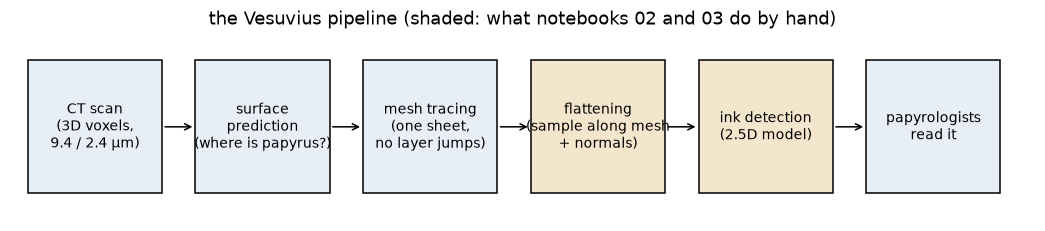

In [2]:
fig, ax = plt.subplots(figsize=(12, 2.2)); ax.axis('off')
steps = ['CT scan\n(3D voxels,\n9.4 / 2.4 µm)', 'surface\nprediction\n(where is papyrus?)', 'mesh tracing\n(one sheet,\nno layer jumps)',
         'flattening\n(sample along mesh\n+ normals)', 'ink detection\n(2.5D model)', 'papyrologists\nread it']
for i, s in enumerate(steps):
    ax.add_patch(plt.Rectangle((i * 2, 0), 1.6, 1, fc='#f3e6cc' if i in (3, 4) else '#e8eef6', ec='k'))
    ax.text(i * 2 + .8, .5, s, ha='center', va='center', fontsize=9)
    if i < len(steps) - 1: ax.annotate('', (i * 2 + 2, .5), (i * 2 + 1.6, .5), arrowprops=dict(arrowstyle='->'))
ax.set_xlim(-.2, 12); ax.set_ylim(-.2, 1.2); ax.set_title('the Vesuvius pipeline (shaded: what notebooks 02 and 03 do by hand)'); plt.show()

## 2. The data

The scans live in `s3://vesuvius-challenge-open-data/` (anonymous read, CC-BY-NC 4.0), one folder per scroll.
Each scan is an **OME-Zarr** pyramid: level 0 is full resolution, every further level halves each axis.
The array axes are `(z, y, x)`; `z` runs along the scroll's long axis.

In [3]:
for lvl in range(6):
    a = vlab.scroll_volume(lvl)
    print(f"level {lvl}: shape {a.shape}, {np.prod(a.shape) / 1e9:8.2f} GB as uint8, chunks {a.chunks}")

level 0: shape (20974, 6621, 6621),   919.45 GB as uint8, chunks (128, 128, 128)


level 1: shape (10487, 3311, 3311),   114.97 GB as uint8, chunks (128, 128, 128)


level 2: shape (5244, 1656, 1656),    14.38 GB as uint8, chunks (128, 128, 128)


level 3: shape (2622, 828, 828),     1.80 GB as uint8, chunks (128, 128, 128)


level 4: shape (1311, 414, 414),     0.22 GB as uint8, chunks (128, 128, 128)


level 5: shape (656, 207, 207),     0.03 GB as uint8, chunks (128, 128, 128)


Level 0 is about **920 GB**. That is why everything here streams small pieces: a slice at level 4 is a handful of
128³ chunks.

## 3. A cross-section: the spiral

slice (414, 414) in 2.8s (cached after the first run); value range 0..209


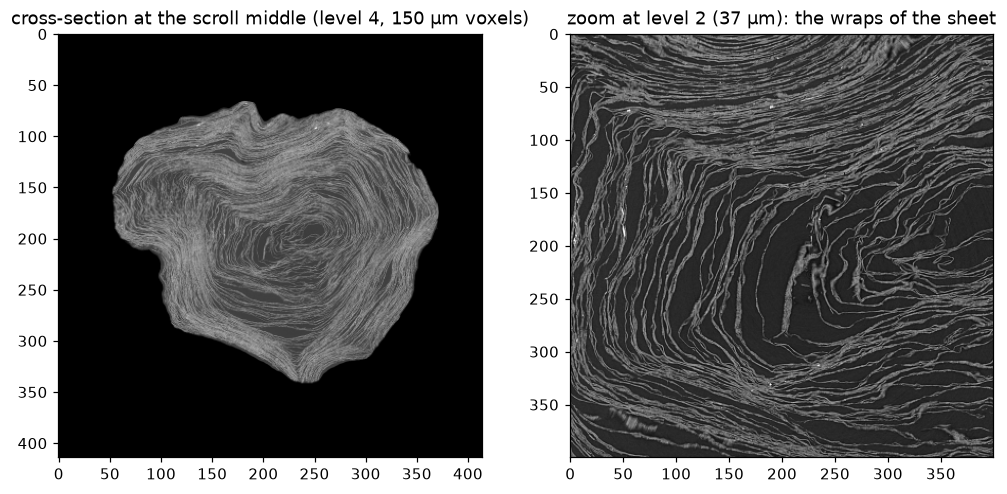

In [4]:
v4 = vlab.scroll_volume(4)
t = time.time(); sl = vlab.crop(v4, 'v4', v4.shape[0] // 2)
print(f'slice {sl.shape} in {time.time() - t:.1f}s (cached after the first run); value range {sl.min()}..{sl.max()}')
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(sl); ax[0].set_title('cross-section at the scroll middle (level 4, 150 µm voxels)')
v2 = vlab.scroll_volume(2); z2 = v2.shape[0] // 2
zoomed = vlab.crop(v2, 'v2mid', z2, slice(600, 1000), slice(600, 1000))
ax[1].imshow(zoomed); ax[1].set_title('zoom at level 2 (37 µm): the wraps of the sheet')
plt.show()

The bright spiral is papyrus; dark is air. In the zoom you can count wraps, and see where they touch or are crushed
together. Following **one** wrap through thousands of such slices, without jumping to its neighbour, is the
segmentation problem (notebook 02 uses a sheet someone already traced).

## 4. Along the scroll

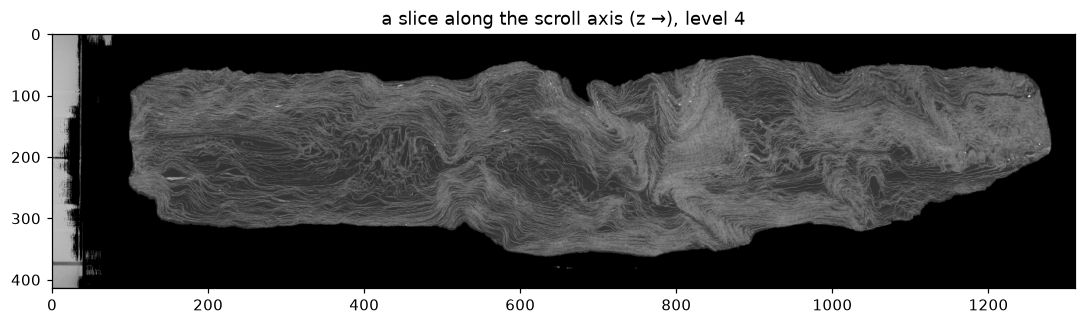

In [5]:
side = vlab.crop(v4, 'v4side', slice(None), v4.shape[1] // 2)
plt.figure(figsize=(12, 3)); plt.imshow(side.T, aspect='auto'); plt.title('a slice along the scroll axis (z →), level 4'); plt.show()

## Check yourself

1. Why does the challenge use a pyramid instead of one big array?
2. Ink is carbon on carbon. Why does that make it harder than reading pencil on paper in an X-ray?
3. In the zoomed cross-section, where would a tracer most likely jump from one wrap to the next?